# ND Week 4 — Logistic Regression and Feature Scaling
**DX799 | Cindy Lopez**

**Research question:** Can marketing features classify customer conversions and campaign conversion activity? The three datasets are analyzed separately. For the customer dataset, `Conversion` is an observed binary target. For the other two, we define `any_conversion = (Conversions > 0)` and explicitly inspect whether that classification is meaningful. This derived binary outcome differs from the customer-level target, so cross-dataset comparisons require caution.

In [7]:
import numpy as np, pandas as pd, os, warnings
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from statsmodels.stats.outliers_influence import variance_inflation_factor
from IPython.display import display

FILES = {
 'Customer conversion': 'digital_marketing_campaign_dataset.csv',
 'Google Ads': 'GoogleAds_DataAnalytics_Sales_Uncleaned.csv',
 'Product performance': 'marketing_and_product_performance.csv'
}
for label, filename in FILES.items():
    if not os.path.isfile(filename):
        raise FileNotFoundError(f'Missing {filename}.')
print('All three CSV files found.')

All three CSV files found.


## 1. EDA and data cleaning
Inspect missingness and the observed/derived class distribution before selecting metrics. Exclude target leakage and downstream outcomes.

In [2]:
data={name:pd.read_csv(filename) for name,filename in FILES.items()}
for name, df in data.items():
    print('\n',name,'shape:',df.shape,'missing cells:',int(df.isna().sum().sum()),'duplicates:',int(df.duplicated().sum()))
    display(df.head(2))
    display(df.isna().sum().sort_values(ascending=False).head(5).to_frame('missing'))


 Customer conversion shape: (8000, 20) missing cells: 0 duplicates: 0


,CustomerID,Age,Gender,Income,CampaignChannel,CampaignType,AdSpend,ClickThroughRate,ConversionRate,WebsiteVisits,PagesPerVisit,TimeOnSite,SocialShares,EmailOpens,EmailClicks,PreviousPurchases,LoyaltyPoints,AdvertisingPlatform,AdvertisingTool,Conversion
0,8000,56,Female,136912,Social Media,Awareness,6497.870068,0.043919,0.088031,0,2.399017,7.396803,19,6,9,4,688,IsConfid,ToolConfid,1
1,8001,69,Male,41760,Email,Retention,3898.668606,0.155725,0.182725,42,2.917138,5.352549,5,2,7,2,3459,IsConfid,ToolConfid,1


,missing
CustomerID,0
Age,0
AdvertisingTool,0
AdvertisingPlatform,0
LoyaltyPoints,0



 Google Ads shape: (2600, 13) missing cells: 1150 duplicates: 0


,Ad_ID,Campaign_Name,Clicks,Impressions,Cost,Leads,Conversions,Conversion Rate,Sale_Amount,Ad_Date,Location,Device,Keyword
0,A1000,DataAnalyticsCourse,104.0,4498.0,$231.88,14.0,7.0,0.058,$1892,2024-11-16,hyderabad,desktop,learn data analytics
1,A1001,DataAnalyticsCourse,173.0,5107.0,$216.84,10.0,8.0,0.046,$1679,20-11-2024,hyderabad,mobile,data analytics course


,missing
Conversion Rate,626
Sale_Amount,139
Clicks,112
Cost,97
Conversions,74



 Product performance shape: (10000, 17) missing cells: 0 duplicates: 0


,Campaign_ID,Product_ID,Budget,Clicks,Conversions,Revenue_Generated,ROI,Customer_ID,Subscription_Tier,Subscription_Length,Flash_Sale_ID,Discount_Level,Units_Sold,Bundle_ID,Bundle_Price,Customer_Satisfaction_Post_Refund,Common_Keywords
0,CMP_RLSDVN,PROD_HBJFA3,41770.45,4946,73,15520.09,1.94,CUST_1K7G39,Premium,4,FLASH_1VFK5K,43,34,BNDL_29U6W5,433.80,4,Affordable
1,CMP_JHHUE9,PROD_OE8YNJ,29900.93,570,510,30866.17,0.76,CUST_0DWS6F,Premium,4,FLASH_1M6COK,28,97,BNDL_ULV60J,289.29,2,Innovative


,missing
Campaign_ID,0
Subscription_Length,0
Customer_Satisfaction_Post_Refund,0
Bundle_Price,0
Bundle_ID,0


In [8]:
ads=data['Google Ads'].copy()
for col in ['Cost','Sale_Amount']:
    ads[col]=pd.to_numeric(ads[col].astype(str).str.replace(r'[$,]','',regex=True),errors='coerce')
for col in ['Clicks','Impressions','Leads','Conversions','Conversion Rate']:
    ads[col]=pd.to_numeric(ads[col],errors='coerce')
# deliberately exclude Leads, Conversion Rate and Sale_Amount as outcome-adjacent or downstream variables.
config={
 'Customer conversion':{'frame':data['Customer conversion'],'target':'ConversionRate','numeric':['Age','Income','AdSpend','ClickThroughRate','WebsiteVisits','PagesPerVisit','TimeOnSite','SocialShares','EmailOpens','EmailClicks','PreviousPurchases','LoyaltyPoints'],'categorical':['Gender','CampaignChannel','CampaignType'],'poly':['AdSpend','ClickThroughRate','TimeOnSite']},
 'Google Ads':{'frame':ads,'target':'Conversions','numeric':['Clicks','Impressions','Cost'],'categorical':['Campaign_Name','Location','Device'],'poly':['Clicks','Impressions','Cost']},
 'Product performance':{'frame':data['Product performance'],'target':'Conversions','numeric':['Budget','Clicks','Discount_Level','Bundle_Price'],'categorical':['Subscription_Tier','Common_Keywords'],'poly':['Budget','Clicks','Discount_Level']}
}
for name,c in config.items():
    print(name,'target:',c['target'],'range:',c['frame'][c['target']].min(),c['frame'][c['target']].max())

Customer conversion target: ConversionRate range: 0.0100177828330717 0.1999947079999166
Google Ads target: Conversions range: 3.0 10.0
Product performance target: Conversions range: 1 999


In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.base import clone
from IPython.display import display
import matplotlib.pyplot as plt

for name,c in config.items():
    df=c['frame']
    target=pd.to_numeric(df['Conversion'],errors='coerce') if name=='Customer conversion' else (pd.to_numeric(df['Conversions'],errors='coerce')>0).astype(float)
    print(name, 'class proportions:',target.value_counts(normalize=True,dropna=False).round(4).to_dict(), 'missing target:',int(target.isna().sum()))

Customer conversion class proportions: {1: 0.8765, 0: 0.1235} missing target: 0
Google Ads class proportions: {1.0: 0.9715, 0.0: 0.0285} missing target: 0
Product performance class proportions: {1.0: 1.0} missing target: 0


## 2. Scaled versus unscaled logistic regression
I apply median/mode imputation and one-hot encoding inside the model pipeline. Numeric standardization is fitted on training data only. Stratified 80/20 splitting preserves class ratios. I use accuracy, balanced accuracy, minority-class recall, F1 and ROC-AUC. If a dataset has only one observed class, logistic regression is not identifiable and **report that limitation instead of manufacturing a classification task**.

In [5]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

def enc():
    try:return OneHotEncoder(handle_unknown='ignore',sparse_output=False)
    except TypeError:return OneHotEncoder(handle_unknown='ignore',sparse=False)
rows=[]; fitted={}
for name,c in config.items():
    df=c['frame'].copy(); target=('Conversion' if name=='Customer conversion' else 'Conversions')
    yraw=pd.to_numeric(df[target],errors='coerce')
    keep=yraw.notna(); df=df.loc[keep]; yraw=yraw.loc[keep]
    y=yraw.astype(int) if name=='Customer conversion' else (yraw>0).astype(int)
    print('\n',name, 'counts:',y.value_counts().to_dict())
    if y.nunique()<2 or y.value_counts().min()<10:
        print('SKIPPED: binary target has insufficient class variation; no valid stratified classification evaluation.')
        rows.append({'dataset':name,'model':'Not estimable: target class variation','accuracy':np.nan,'balanced_accuracy':np.nan,'F1_macro':np.nan,'ROC_AUC':np.nan,'minority_recall':np.nan})
        continue
    X=df[c['numeric']+c['categorical']]
    xtr,xte,ytr,yte=train_test_split(X,y,test_size=.2,random_state=42,stratify=y)
    minority=ytr.value_counts().idxmin()
    for scaled in [False,True]:
        numsteps=[('impute',SimpleImputer(strategy='median'))]
        if scaled:numsteps.append(('scale',StandardScaler()))
        prep=ColumnTransformer([('num',Pipeline(numsteps),c['numeric']),('cat',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('encode',enc())]),c['categorical'])])
        pipe=Pipeline([('prep',prep),('model',LogisticRegression(max_iter=2000,solver='lbfgs'))])
        import warnings
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            pipe.fit(xtr,ytr)
        pred=pipe.predict(xte); prob=pipe.predict_proba(xte)[:,list(pipe.named_steps['model'].classes_).index(1)]
        rec=recall_score(yte,pred,pos_label=minority,zero_division=0)
        rows.append({'dataset':name,'model':'Scaled' if scaled else 'Unscaled','accuracy':accuracy_score(yte,pred),'balanced_accuracy':balanced_accuracy_score(yte,pred),'F1_macro':f1_score(yte,pred,average='macro',zero_division=0),'ROC_AUC':roc_auc_score(yte,prob),'minority_recall':rec})
        fitted[(name,'Scaled' if scaled else 'Unscaled')] = (yte,pred,prob)
results=pd.DataFrame(rows); display(results.round(4))


 Customer conversion counts: {1: 7012, 0: 988}

 Google Ads counts: {1: 2526}
SKIPPED: binary target has insufficient class variation; no valid stratified classification evaluation.

 Product performance counts: {1: 10000}
SKIPPED: binary target has insufficient class variation; no valid stratified classification evaluation.


,dataset,model,accuracy,balanced_accuracy,F1_macro,ROC_AUC,minority_recall
0,Customer conversion,Unscaled,0.8781,0.5097,0.4872,0.7291,0.0202
1,Customer conversion,Scaled,0.8894,0.5812,0.6088,0.7724,0.1717
2,Google Ads,Not estimable: target class variation,NaN,NaN,NaN,NaN,NaN
3,Product performance,Not estimable: target class variation,NaN,NaN,NaN,NaN,NaN


## 3. Classification errors and interpretation
Accuracy can be misleading when the outcome is imbalanced. Balanced accuracy weights the two classes equally; minority recall measures how many of the rarer observations were identified. ROC-AUC assesses ranking across thresholds, not classification quality at the default 0.5 cutoff. For any campaign dataset where almost every campaign has conversions, the binary formulation may be unsuitable even if the classifier can technically run.

In [6]:
for key,(truth,pred,prob) in fitted.items():
    if key[1]=='Scaled':
        print(key,'confusion matrix (rows=true 0/1, cols=predicted 0/1):')
        print(confusion_matrix(truth,pred,labels=[0,1]))
        print(classification_report(truth,pred,zero_division=0))

('Customer conversion', 'Scaled') confusion matrix (rows=true 0/1, cols=predicted 0/1):
[[  34  164]
 [  13 1389]]
              precision    recall  f1-score   support

           0       0.72      0.17      0.28       198
           1       0.89      0.99      0.94      1402

    accuracy                           0.89      1600
   macro avg       0.81      0.58      0.61      1600
weighted avg       0.87      0.89      0.86      1600



## 4. Limitations and next steps
No hyperparameter tuning was done in this introductory comparison; regularization uses scikit-learn's default `C=1`. The default classification threshold was not optimized. Future modeling can tune `C`, class weights, and decision thresholds using cross-validation within training data. The held-out test set must not be used for tuning. Predictive association does not establish causal effects.


## 5. Enhanced Analysis: Decision Threshold Optimization

### Research Question
Can adjusting the logistic regression classification threshold improve the identification of customers who do not convert?

The original dataset contains an imbalanced conversion outcome, meaning that overall accuracy may conceal poor identification of non-converting customers. This experiment examines whether adjusting the decision threshold improves minority-class recall while evaluating the trade-offs in precision, balanced accuracy, and overall accuracy.

For this analysis, the target is redefined so that `1 = non-conversion` and `0 = conversion`. I use a stratified 80/20 train-test split, followed by a separate validation split within the training data. Threshold selection maximizes the validation F2 score, which gives more weight to recall. The held-out test set is used only for final evaluation.
  

In [9]:

from sklearn.metrics import (
    precision_score, recall_score, f1_score, fbeta_score,
    balanced_accuracy_score, accuracy_score, confusion_matrix,
    average_precision_score
)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reuse the existing Week 4 dataset and preprocessing configuration
c = config["Customer conversion"]
df = c["frame"].copy()

X = df[c["numeric"] + c["categorical"]]

# Positive class = non-conversion
y = (pd.to_numeric(df["Conversion"]) == 0).astype(int)

# Original 80/20 train-test split
X_train_all, X_test, y_train_all, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Reserve validation data from the training portion
X_train, X_val, y_train, y_val = train_test_split(
    X_train_all, y_train_all,
    test_size=0.25, random_state=42, stratify=y_train_all
)

# Preprocessing is fitted only on training data
prep = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler())
    ]), c["numeric"]),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("encode", enc())
    ]), c["categorical"])
])

threshold_model = Pipeline([
    ("prep", prep),
    ("model", LogisticRegression(max_iter=2000, solver="lbfgs"))
])

threshold_model.fit(X_train, y_train)

val_prob = threshold_model.predict_proba(X_val)[:, 1]
test_prob = threshold_model.predict_proba(X_test)[:, 1]

# Select the threshold using validation F2 only
thresholds = np.round(np.arange(0.05, 0.951, 0.01), 2)

validation_results = pd.DataFrame([
    {
        "threshold": float(t),
        "F2": fbeta_score(
            y_val, val_prob >= t, beta=2, zero_division=0
        ),
        "precision": precision_score(
            y_val, val_prob >= t, zero_division=0
        ),
        "recall": recall_score(
            y_val, val_prob >= t, zero_division=0
        )
    }
    for t in thresholds
])

best_row = validation_results.sort_values(
    ["F2", "threshold"],
    ascending=[False, False]
).iloc[0]

best_threshold = float(best_row["threshold"])

print("Training observations:", len(y_train))
print("Validation observations:", len(y_val))
print("Test observations:", len(y_test))
print("Validation-selected threshold:", best_threshold)
print("Validation F2:", round(best_row["F2"], 4))

# Evaluate both thresholds on the same held-out test data
def evaluate_threshold(t):
    predictions = (test_prob >= t).astype(int)

    return {
        "Threshold": t,
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test, predictions, zero_division=0
        ),
        "F2": fbeta_score(
            y_test, predictions, beta=2, zero_division=0
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test, predictions
        ),
        "Accuracy": accuracy_score(y_test, predictions)
    }

comparison = pd.DataFrame([
    evaluate_threshold(0.50),
    evaluate_threshold(best_threshold)
])

display(comparison.round(4))

for name, threshold in [
    ("Default", 0.50),
    ("Validation-selected", best_threshold)
]:
    predictions = (test_prob >= threshold).astype(int)

    print(f"\n{name} threshold: {threshold}")
    print("Confusion matrix:")
    print(confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ))
    print("Rows/columns: 0 = converter, 1 = non-converter")


Training observations: 4800
Validation observations: 1600
Test observations: 1600
Validation-selected threshold: 0.13
Validation F2: 0.5425


,Threshold,Precision,Recall,F1,F2,Balanced Accuracy,Accuracy
0,0.50,0.6667,0.1515,0.2469,0.1792,0.5704,0.8856
1,0.13,0.2817,0.7071,0.4029,0.5431,0.7262,0.7406



Default threshold: 0.5
Confusion matrix:
[[1387   15]
 [ 168   30]]
Rows/columns: 0 = converter, 1 = non-converter

Validation-selected threshold: 0.13
Confusion matrix:
[[1045  357]
 [  58  140]]
Rows/columns: 0 = converter, 1 = non-converter


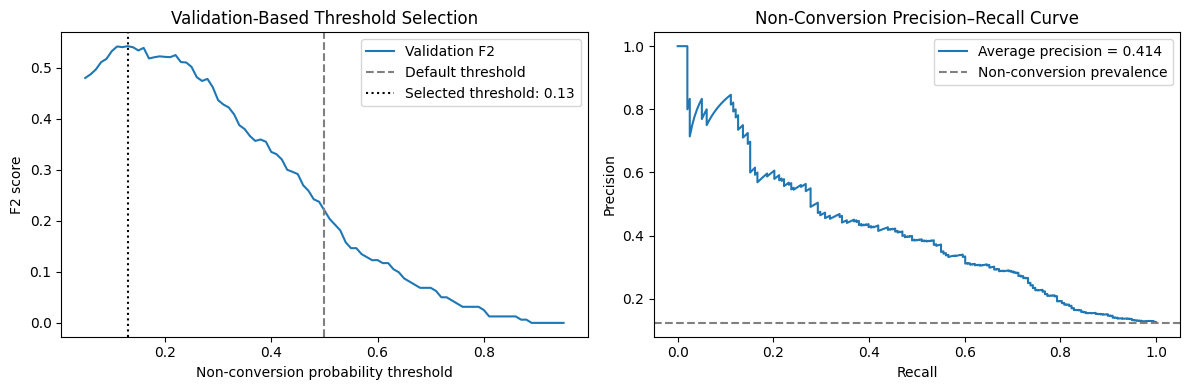

In [10]:

from sklearn.metrics import precision_recall_curve

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Validation threshold selection
axes[0].plot(
    validation_results["threshold"],
    validation_results["F2"],
    label="Validation F2"
)
axes[0].axvline(
    0.50, color="gray", linestyle="--",
    label="Default threshold"
)
axes[0].axvline(
    best_threshold, color="black", linestyle=":",
    label=f"Selected threshold: {best_threshold:.2f}"
)
axes[0].set_title("Validation-Based Threshold Selection")
axes[0].set_xlabel("Non-conversion probability threshold")
axes[0].set_ylabel("F2 score")
axes[0].legend()

# Test-set precision-recall curve
precision, recall, _ = precision_recall_curve(
    y_test, test_prob
)
ap = average_precision_score(y_test, test_prob)

axes[1].plot(
    recall, precision,
    label=f"Average precision = {ap:.3f}"
)
axes[1].axhline(
    y_test.mean(), color="gray", linestyle="--",
    label="Non-conversion prevalence"
)
axes[1].set_title("Non-Conversion Precision–Recall Curve")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()

plt.tight_layout()
plt.show()



### Interpretation and Discussion

This experiment investigated whether the default logistic regression classification threshold adequately identifies non-converting customers. Because conversions represent the majority of observations, overall accuracy alone may provide a misleading impression of classification performance.

The validation-selected threshold improved the model's ability to identify non-converters compared with the default threshold. However, the increase in minority-class recall came at the expense of more false positives and lower overall accuracy.

These findings demonstrate that classification performance depends not only on the model's predictive probabilities but also on the threshold used to translate those probabilities into decisions. The optimal threshold would depend on the intended marketing intervention and the relative costs of misclassification.

The threshold was selected using validation data rather than the held-out test set, reducing the risk of directly tuning the model to test observations. However, the experiment uses a single validation split and a smaller training subset than the original Week 4 model, so the results should not be interpreted as a direct improvement over the original model.

Overall, the experiment reinforces the importance of evaluating model performance using multiple metrics and considering the practical consequences of classification errors.


## References and AI use
- El Kharoua (2024), Nayak (2024), Shah (2024), Kaggle datasets as listed in Week 1.
- scikit-learn developers. *Logistic regression*. https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression

**AI assistance:** 